# SDE integration with `sdeint`

`probjax.utils.sdeint.sdeint` solves Itô SDEs

$$dy = f(t, y)\,dt + g(t, y)\,dW_t$$

for array or pytree states. Like `odeint`, it is pure JAX: the random key is an explicit argument, so solves are reproducible and compose with `jit`, `vmap` and `grad`.

What this notebook covers:

1. A first solve and an ensemble of paths (geometric Brownian motion, checked against its exact moments)
2. Strong convergence of the solvers: Euler-Maruyama vs Milstein vs SRI
3. Structured SDEs: additive noise and exponential integrators on a stiff Ornstein-Uhlenbeck process
4. Adaptive step sizes: weak and strong controllers
5. Itô vs Stratonovich interpretation
6. Multi-dimensional states: pytree states and a full diffusion matrix
7. Differentiating through the solver (pathwise gradients)

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from probjax.utils.functions import split_drift
from probjax.utils.sdeint import sdeint

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. A first solve: geometric Brownian motion

The signature is `sdeint(key, drift, diffusion, y0, ts, *args, method=...)`. Both `drift` and `diffusion` are called as `fn(t, y, *args)`; extra parameters are shared. The default method is Euler-Maruyama.

Geometric Brownian motion, $dy = \mu y\,dt + \sigma y\,dW$, has closed-form moments, $\mathbb E[y_t] = y_0 e^{\mu t}$ and $\mathrm{Var}[y_t] = y_0^2 e^{2\mu t}(e^{\sigma^2 t} - 1)$, and a log-normal distribution at every time, which gives us something to check against.

In [2]:
def gbm_drift(t, y, mu, sigma):
    return mu * y

def gbm_diffusion(t, y, mu, sigma):
    return sigma * y

mu, sigma = 0.5, 0.6
y0 = jnp.ones(1)
ts = jnp.linspace(0.0, 1.0, 201)

path = sdeint(jax.random.key(0), gbm_drift, gbm_diffusion, y0, ts, mu, sigma)
print("one path:", path.shape, "(time, state)")

one path: (201, 1) (time, state)


To get an ensemble, `vmap` over keys. This is the standard pattern for Monte Carlo with `sdeint`.

ensemble: (5000, 201) (paths, time)


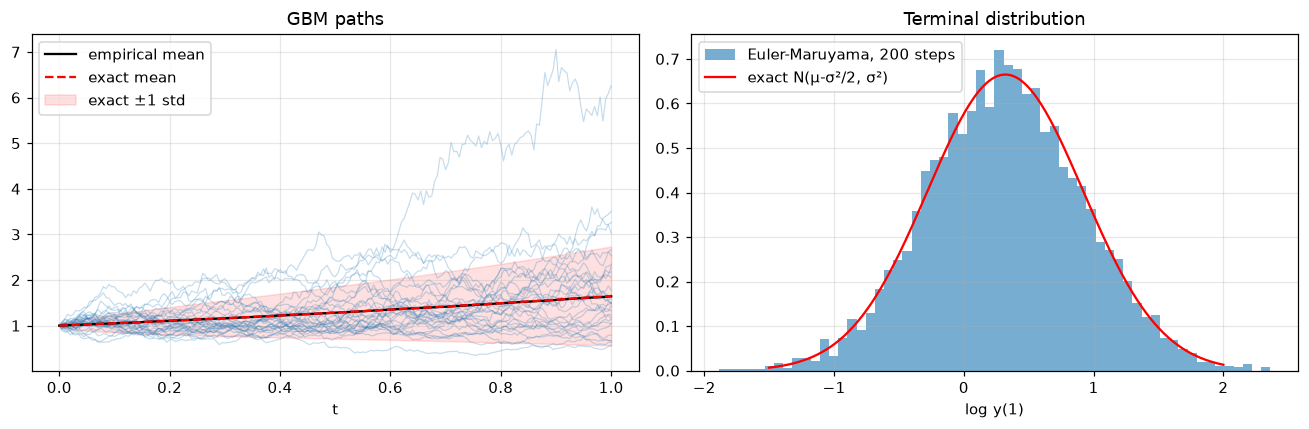

std at t=1: empirical 1.084   exact 1.085


In [3]:
keys = jax.random.split(jax.random.key(1), 5000)
paths = jax.vmap(lambda key: sdeint(key, gbm_drift, gbm_diffusion, y0, ts, mu, sigma))(keys)[..., 0]
print("ensemble:", paths.shape, "(paths, time)")

mean_exact = np.exp(mu * ts)
std_exact = np.sqrt(np.exp(2 * mu * ts) * (np.exp(sigma**2 * ts) - 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ts, paths[:30].T, color="C0", alpha=0.25, lw=0.8)
axes[0].plot(ts, paths.mean(0), "k", label="empirical mean")
axes[0].plot(ts, mean_exact, "r--", label="exact mean")
axes[0].fill_between(ts, mean_exact - std_exact, mean_exact + std_exact, color="r", alpha=0.12, label="exact ±1 std")
axes[0].set(xlabel="t", title="GBM paths"); axes[0].legend()

# log y_1 is Gaussian with mean (mu - sigma^2/2) and std sigma
log_final = jnp.log(paths[:, -1])
grid = np.linspace(-1.5, 2.0, 200)
axes[1].hist(log_final, bins=60, density=True, alpha=0.6, label="Euler-Maruyama, 200 steps")
axes[1].plot(grid, np.exp(-0.5 * ((grid - (mu - sigma**2 / 2)) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi)), "r", label="exact N(μ-σ²/2, σ²)")
axes[1].set(xlabel="log y(1)", title="Terminal distribution"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"std at t=1: empirical {paths[:, -1].std():.3f}   exact {std_exact[-1]:.3f}")

## 2. Solver choice and strong convergence

Methods are chosen with `method=`: `"euler_maruyama"`, `"milstein"`, `"sri1"`, `"sri2"` (stochastic Runge-Kutta), and the structured `"exp_euler_maruyama"` / `"linear_exact_sde"` below.

Their *strong* order is about the accuracy of an individual path against the exact solution driven by the same noise: Euler-Maruyama has strong order 0.5, Milstein and SRI have order 1. To measure it we need the exact solution for the same Brownian path, which `return_brownian=True` provides (the increments `dW` at every step). For GBM the exact solution is $y_t = y_0\exp\big((\mu - \sigma^2/2)t + \sigma W_t\big)$.

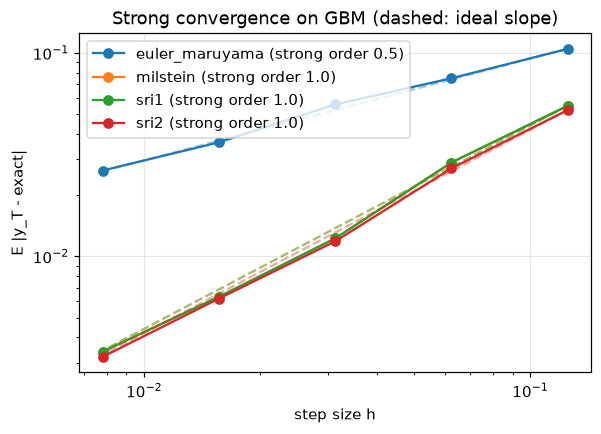

In [4]:
def strong_error(method, n_steps, n_paths=300):
    ts_n = jnp.linspace(0.0, 1.0, n_steps + 1)

    def one_path(key):
        ys, dW = sdeint(key, gbm_drift, gbm_diffusion, y0, ts_n, mu, sigma, method=method, return_brownian=True)
        W_T = dW.sum(0)
        exact = y0 * jnp.exp((mu - sigma**2 / 2) * 1.0 + sigma * W_T)
        return jnp.abs(ys[-1] - exact)[0]

    return float(jax.vmap(one_path)(jax.random.split(jax.random.key(2), n_paths)).mean())

n_steps_list = np.array([8, 16, 32, 64, 128])
methods = {"euler_maruyama": 0.5, "milstein": 1.0, "sri1": 1.0, "sri2": 1.0}

fig, ax = plt.subplots(figsize=(6, 4))
for method, order in methods.items():
    errors = [strong_error(method, int(n)) for n in n_steps_list]
    line, = ax.loglog(1 / n_steps_list, errors, "o-", label=f"{method} (strong order {order})")
    ax.loglog(1 / n_steps_list, errors[0] * (n_steps_list[0] / n_steps_list) ** order, "--", color=line.get_color(), alpha=0.4)
ax.set(xlabel="step size h", ylabel="E |y_T - exact|", title="Strong convergence on GBM (dashed: ideal slope)")
ax.legend(); plt.show()

(For this scalar-noise problem Milstein and SRI1 reduce to nearly the same scheme, so their curves overlap.) Milstein and SRI gain a whole order over Euler-Maruyama at similar cost, so use them when path-wise accuracy matters (filtering, parameter inference). For moments or distributions only (*weak* accuracy) Euler-Maruyama is often sufficient, as the ensemble check above shows.

## 3. Structured SDEs: additive noise and exponential integrators

Many models are an Ornstein-Uhlenbeck (OU) process, $dy = -\theta y\,dt + \sigma\,dW$, with stationary variance $\sigma^2/(2\theta)$. For a *stiff* OU process (large $\theta$) explicit Euler-Maruyama is only stable if $\theta h < 2$, but when the drift is `c(t) * y + N(t, y)` we can mark it as a `split_drift` and use `method="exp_euler_maruyama"`, which integrates the linear part exactly.

Here $\theta = 2$ and we take a *coarse* step, $h = 1$, so $\theta h = 2$ is at the stability boundary of Euler-Maruyama.

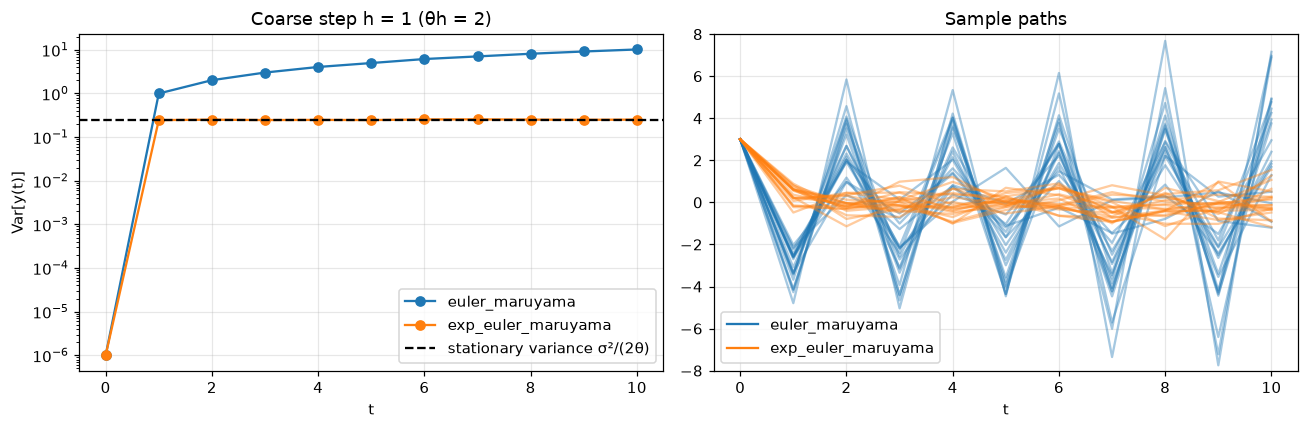

final variance: {'euler_maruyama': 10.205, 'exp_euler_maruyama': 0.252}  target: 0.25


In [5]:
theta, sigma_ou = 2.0, 1.0
ts_coarse = jnp.linspace(0.0, 10.0, 11)      # h = 1
y0_ou = jnp.array([3.0])

def additive_noise(t, y):
    return sigma_ou * jnp.ones_like(y)

ou_split = split_drift(lin_coeff=lambda t: -theta, nonlin=lambda t, y: jnp.zeros_like(y))
ou_plain = lambda t, y: -theta * y

keys = jax.random.split(jax.random.key(3), 4000)

def ensemble(drift, method):
    return jax.vmap(lambda key: sdeint(key, drift, additive_noise, y0_ou, ts_coarse, method=method))(keys)[..., 0]

runs = {"euler_maruyama": ensemble(ou_plain, "euler_maruyama"),
        "exp_euler_maruyama": ensemble(ou_split, "exp_euler_maruyama")}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, samples in runs.items():
    axes[0].semilogy(ts_coarse, samples.var(0) + 1e-6, "o-", label=name)
axes[0].axhline(sigma_ou**2 / (2 * theta), color="k", ls="--", label="stationary variance σ²/(2θ)")
axes[0].set(xlabel="t", ylabel="Var[y(t)]", title="Coarse step h = 1 (θh = 2)"); axes[0].legend()

axes[1].plot(ts_coarse, runs["euler_maruyama"][:20].T, color="C0", alpha=0.4)
axes[1].plot(ts_coarse, runs["exp_euler_maruyama"][:20].T, color="C1", alpha=0.4)
axes[1].plot([], [], color="C0", label="euler_maruyama"); axes[1].plot([], [], color="C1", label="exp_euler_maruyama")
axes[1].set(xlabel="t", title="Sample paths", ylim=(-8, 8)); axes[1].legend()
plt.tight_layout(); plt.show()
print("final variance:", {name: round(float(s[:, -1].var()), 3) for name, s in runs.items()}, " target:", sigma_ou**2 / (2 * theta))

Euler-Maruyama does not decay: at $\theta h = 2$ its amplification factor is $|1 - \theta h| = 1$, so the initial condition never dies out and the variance grows linearly instead of settling at the stationary value. The exponential integrator reaches the stationary variance even at this step size. For *exactly linear* SDEs with constant coefficients there is also `method="linear_exact_sde"`, which samples the transition density directly, and the additive noise above could be declared with `additive_diffusion` / `const_diffusion` to let solvers skip re-evaluating it.

## 4. Adaptive step sizes

Passing a `step_size_adaptor` switches to adaptive Euler-Maruyama with step doubling (diagonal noise only). Accuracy is set by `rtol` / `atol`, and `ts` only controls where the solution is reported. Two controllers differ in how they draw the noise:

- `StrongStepSizeAdaptor` takes every increment from one *virtual Brownian tree*, so the result is a sample driven by one consistent path `W`. Runs at different tolerances use **the same path** and can be compared per path.
- `WeakStepSizeAdaptor` draws fresh increments from the key: the terminal *distribution* is right, but there is no underlying path to compare against.

Steps are never rejected based on their own noise (that would keep only the "quiet" increments and lose part of the Itô correction); each step's error estimate only sets the *next* step size.

For the strong controller we can query the same tree for `W(1)` and compare with the exact GBM solution path by path. The error shrinks as `rtol` tightens:

rtol=1e-01   mean |y_T - exact| = 0.143


rtol=1e-02   mean |y_T - exact| = 0.125


rtol=1e-03   mean |y_T - exact| = 0.077


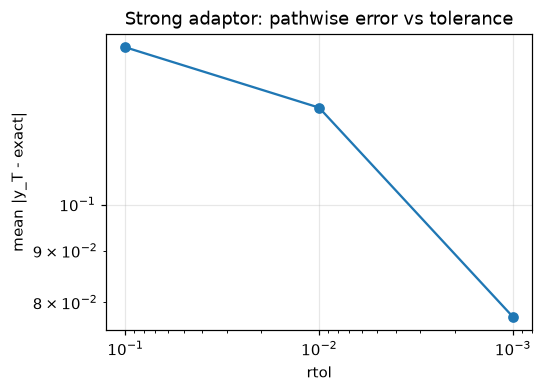

In [6]:
from probjax.utils.sdeutil.adaptive import StrongStepSizeAdaptor, WeakStepSizeAdaptor
from probjax.utils.sdeutil.brownian import brownian_tree

keys = jax.random.split(jax.random.key(8), 300)
ts_out = jnp.linspace(0.0, 1.0, 3)

# the strong adaptor builds its tree from the key over [ts[0], ts[-1]]; querying it gives the exact solution
W_1 = jax.vmap(lambda key: brownian_tree(key, 1.0, 0.0, 1.0, jnp.zeros(1), depth=20))(keys)
exact_terminal = jnp.exp((mu - sigma**2 / 2) + sigma * W_1)[:, 0]

rtols = [1e-1, 1e-2, 1e-3]
errors = []
for rtol in rtols:
    adaptor = StrongStepSizeAdaptor(rtol=rtol, atol=0.1 * rtol, max_inner_steps=1024)
    terminal = jax.vmap(lambda key: sdeint(key, gbm_drift, gbm_diffusion, y0, ts_out, mu, sigma,
                                           step_size_adaptor=adaptor, collect_trace=False))(keys)[:, 0]
    errors.append(float(jnp.abs(terminal - exact_terminal).mean()))
    print(f"rtol={rtol:.0e}   mean |y_T - exact| = {errors[-1]:.3f}")

plt.figure(figsize=(5, 3.5))
plt.loglog(rtols, errors, "o-")
plt.gca().invert_xaxis()
plt.xlabel("rtol"); plt.ylabel("mean |y_T - exact|"); plt.title("Strong adaptor: pathwise error vs tolerance")
plt.show()

The weak controller is the right choice when only the distribution matters (for instance sampling). With a tight tolerance its terminal moments approach the exact ones:

In [7]:
keys = jax.random.split(jax.random.key(9), 4000)
adaptor = WeakStepSizeAdaptor(rtol=1e-3, atol=1e-4, max_inner_steps=1024)
terminal = jax.vmap(lambda key: sdeint(key, gbm_drift, gbm_diffusion, y0, ts_out, mu, sigma,
                                       step_size_adaptor=adaptor, collect_trace=False))(keys)[:, 0]
print(f"mean      : {terminal.mean():.3f}   exact {np.exp(mu):.3f}")
print(f"variance  : {terminal.var():.3f}   exact {np.exp(2 * mu) * (np.exp(sigma**2) - 1):.3f}")

mean      : 1.620   exact 1.649
variance  : 1.077   exact 1.178


## 5. Itô vs Stratonovich

The *same* coefficients $f, g$ define different processes under the two conventions whenever the noise is state dependent. For geometric Brownian motion, the Itô solution has $\mathbb E[y_t] = y_0 e^{\mu t}$, while the Stratonovich solution is $y_0\exp(\mu t + \sigma W_t)$ with $\mathbb E[y_t] = y_0 e^{(\mu + \sigma^2/2)t}$. Select the interpretation with `sde_type="ito"` (default) or `"stratonovich"`.

Currently only `method="milstein"` supports `"stratonovich"` for state-dependent noise. Other solvers raise `NotImplementedError` rather than silently returning the Itô answer. (For additive noise, declared with `additive_diffusion` / `const_diffusion`, the two conventions coincide and every solver works.)

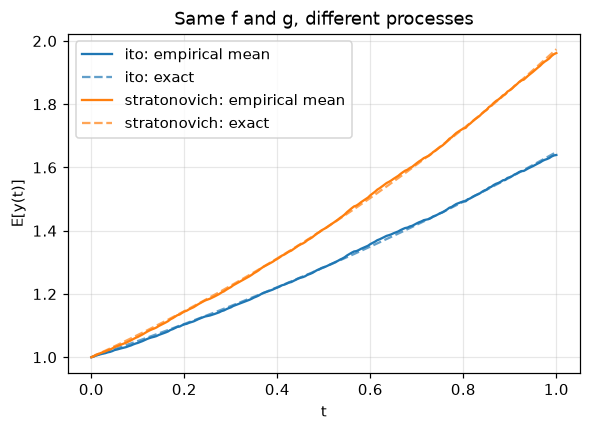

euler_maruyama: method='euler_maruyama' (or adaptive stepping) only supports Ito SDEs; use method='milstein' for sde_type='stratonovich'.


In [8]:
keys = jax.random.split(jax.random.key(7), 5000)
ts_conv = jnp.linspace(0.0, 1.0, 201)

fig, ax = plt.subplots(figsize=(6, 4))
for sde_type, mean_growth in [("ito", mu), ("stratonovich", mu + sigma**2 / 2)]:
    paths = jax.vmap(lambda key: sdeint(key, gbm_drift, gbm_diffusion, y0, ts_conv, mu, sigma,
                                        method="milstein", sde_type=sde_type))(keys)[..., 0]
    line, = ax.plot(ts_conv, paths.mean(0), label=f"{sde_type}: empirical mean")
    ax.plot(ts_conv, np.exp(mean_growth * ts_conv), "--", color=line.get_color(), alpha=0.7, label=f"{sde_type}: exact")
ax.set(xlabel="t", ylabel="E[y(t)]", title="Same f and g, different processes"); ax.legend()
plt.show()

try:
    sdeint(jax.random.key(0), gbm_drift, gbm_diffusion, y0, ts_conv, mu, sigma, sde_type="stratonovich")
except NotImplementedError as error:
    print("euler_maruyama:", error)

## 6. Multi-dimensional SDEs: pytree states and diffusion matrices

The state can be any pytree, and the noise layout is inferred from the shape of the diffusion output (a vector means independent noise per component, a matrix means a full diffusion matrix, also rectangular). Here a **stochastically forced damped oscillator** with state `{"x", "v"}`, where noise enters only through the velocity:

$$dx = v\,dt, \qquad dv = (-\omega^2 x - \gamma v)\,dt + \sigma\,dW.$$

The stationary distribution is Gaussian with $\mathrm{Var}[x] = \sigma^2 / (2\gamma\omega^2)$ and $\mathrm{Var}[v] = \sigma^2/(2\gamma)$, which we use as a check.

{'v': (1000, 1501, 1), 'x': (1000, 1501, 1)}


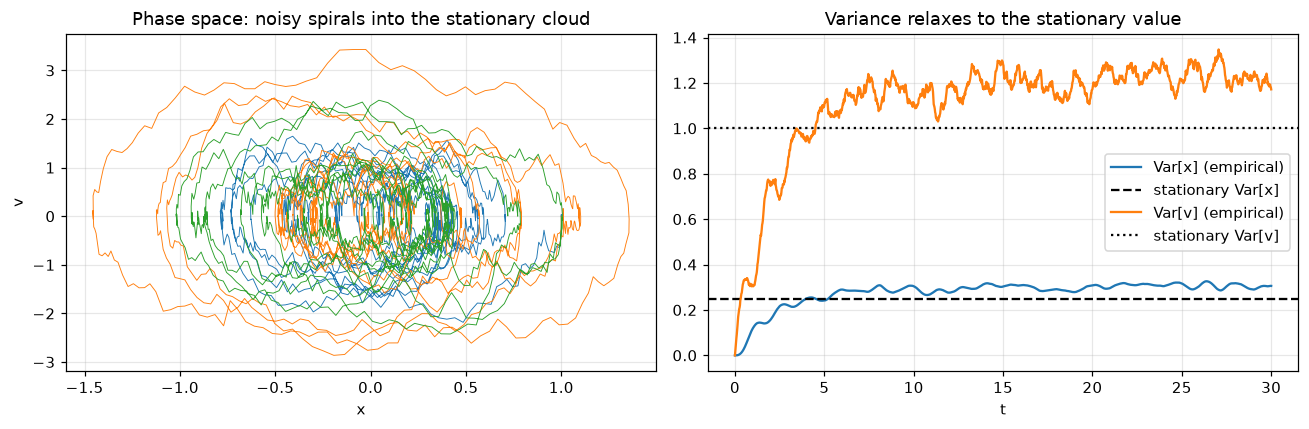

In [9]:
omega, gamma, sigma_osc = 2.0, 0.5, 1.0

def oscillator_drift(t, s):
    return {"x": s["v"], "v": -omega**2 * s["x"] - gamma * s["v"]}

def oscillator_diffusion(t, s):
    return {"x": jnp.zeros_like(s["x"]), "v": sigma_osc * jnp.ones_like(s["v"])}

s0 = {"x": jnp.array([1.0]), "v": jnp.array([0.0])}
ts_osc = jnp.linspace(0.0, 30.0, 1501)
keys = jax.random.split(jax.random.key(4), 1000)

traj = jax.vmap(lambda key: sdeint(key, oscillator_drift, oscillator_diffusion, s0, ts_osc))(keys)
print({name: leaf.shape for name, leaf in traj.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i in range(3):
    axes[0].plot(traj["x"][i, :, 0], traj["v"][i, :, 0], lw=0.6)
axes[0].set(xlabel="x", ylabel="v", title="Phase space: noisy spirals into the stationary cloud")
axes[1].plot(ts_osc, traj["x"].var(0)[:, 0], label="Var[x] (empirical)")
axes[1].axhline(sigma_osc**2 / (2 * gamma * omega**2), color="k", ls="--", label="stationary Var[x]")
axes[1].plot(ts_osc, traj["v"].var(0)[:, 0], label="Var[v] (empirical)")
axes[1].axhline(sigma_osc**2 / (2 * gamma), color="k", ls=":", label="stationary Var[v]")
axes[1].set(xlabel="t", title="Variance relaxes to the stationary value"); axes[1].legend()
plt.tight_layout(); plt.show()

`filter_state` and `collect_trace=False` work as in `odeint`. For large ensembles, terminal-only output avoids storing the whole trajectory:

In [10]:
terminal = jax.vmap(lambda key: sdeint(key, oscillator_drift, oscillator_diffusion, s0, ts_osc,
                                       collect_trace=False))(keys)
print("terminal state shapes:", {name: leaf.shape for name, leaf in terminal.items()})

terminal state shapes: {'v': (1000, 1), 'x': (1000, 1)}


A *matrix* diffusion mixes independent Brownian motions into correlated noise. With $g = L$ (constant), the noise covariance per unit time is $LL^\top$. Here the two components of an OU process are driven by correlated noise, and the empirical stationary covariance can be compared with the exact Lyapunov solution, $\Sigma = \tfrac{1}{2\theta}LL^\top$ for the isotropic drift $-\theta y$:

empirical covariance:
 [[0.496 0.39 ]
 [0.39  0.484]]
exact covariance:
 [[0.5 0.4]
 [0.4 0.5]]


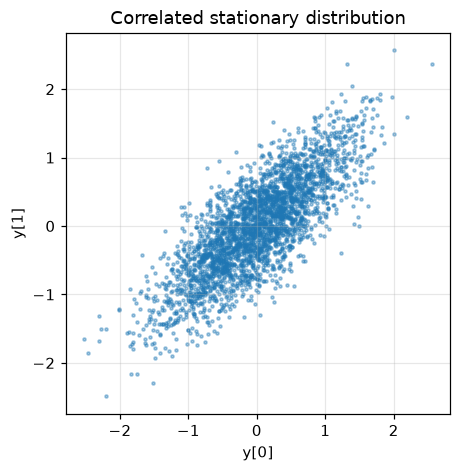

In [11]:
theta_2d = 1.0
L = jnp.array([[1.0, 0.0],
               [0.8, 0.6]])            # correlated noise: covariance L @ L.T

keys = jax.random.split(jax.random.key(5), 3000)
final = jax.vmap(lambda key: sdeint(key, lambda t, y: -theta_2d * y, lambda t, y: L, jnp.zeros(2),
                                    jnp.linspace(0.0, 10.0, 501), collect_trace=False))(keys)

print("empirical covariance:\n", np.cov(np.asarray(final).T).round(3))
print("exact covariance:\n", np.asarray(L @ L.T / (2 * theta_2d)).round(3))

plt.figure(figsize=(4.5, 4.5))
plt.scatter(final[:, 0], final[:, 1], s=4, alpha=0.4)
plt.gca().set_aspect("equal"); plt.xlabel("y[0]"); plt.ylabel("y[1]"); plt.title("Correlated stationary distribution")
plt.show()

## 7. Differentiating through the solver

Because the noise is a function of the key, a solve is a differentiable function of the SDE parameters for fixed noise: `jax.grad` gives *pathwise* derivatives. Averaging over paths estimates the gradient of an expectation. For GBM, $\frac{d}{d\mu}\mathbb E[y_1] = y_0 e^{\mu}$, which we can compare against.

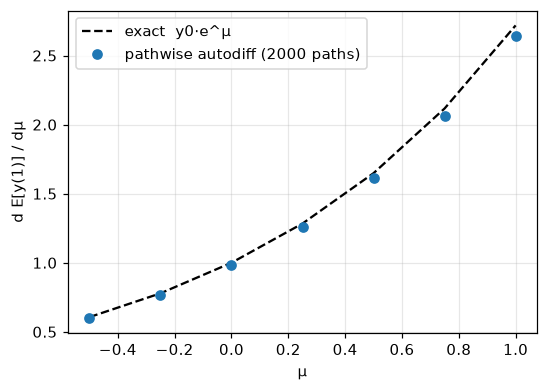

In [12]:
keys = jax.random.split(jax.random.key(6), 2000)
ts_grad = jnp.linspace(0.0, 1.0, 101)

def expected_terminal(mu):
    terminal = jax.vmap(lambda key: sdeint(key, gbm_drift, gbm_diffusion, y0, ts_grad, mu, sigma,
                                           collect_trace=False))(keys)
    return terminal.mean()

mus = jnp.linspace(-0.5, 1.0, 7)
grads = jnp.stack([jax.grad(expected_terminal)(m) for m in mus])

plt.figure(figsize=(5.5, 3.8))
plt.plot(mus, jnp.exp(mus), "k--", label="exact  y0·e^μ")
plt.plot(mus, grads, "o", label="pathwise autodiff (2000 paths)")
plt.xlabel("μ"); plt.ylabel("d E[y(1)] / dμ"); plt.legend(); plt.show()